# 02 · Preparación de datos (v2)
**Caso:** Sistema de recomendación de productos · Nexus Retail SpA

Aplica las **decisiones de negocio acordadas**, limpia los cuatro datasets, construye la variable objetivo `compra(usuario_id, sku)` con **cuatro cortes temporales de 90 días** y genera entrenamiento y validación listos para modelar.

**Decisiones acordadas**

| # | Tema | Decisión |
|---|---|---|
| 1 | Consentimiento | Se usa **solo** a usuarios con `acepta_marketing == 1`. El resto se excluye de todo (compras, clickstream, popularidad) |
| 2 | Stock | Recomendable = activo, precio > 0 y `stock ≥ STOCK_MINIMO` (cubre el atraso de 30 min del ERP) |
| 3 | Costo > precio | Dato sucio: no se usa `costo`; esos SKU se marcan con `precio_sospechoso` y se informan a catálogo |
| 4 | SKU `NX-9xxxx` fuera del catálogo | Se excluyen |
| 5 | Regiones | Se aplica el mapeo de variantes |
| 6 | `comuna` | No es confiable: se confía en `region` y se descarta `comuna` |
| 7 | Categorías `cables` y `cables y adaptadores` | Se unen en `cables y adaptadores` |
| 8 | Marca `N/D`, canal `unknown`, vacíos | Todos pasan a `sin_dato` |
| 9 | Canal `movil` y `app` | Son lo mismo → `app` |
| 10 | Estados | Cuentan como compra `pagado` y `devuelto`; se excluyen `anulado` y `-` |
| 11 | Cantidad ≤ 0 | Se excluye |
| 12 | Usuarios fuera de `usuarios.csv` | Sin consentimiento registrado → quedan fuera por (1) |
| 13 | Usuario `UNKNOWN` (y `invitado`) | Se excluye |
| 14 | Fechas | Formato chileno, día primero |
| 15 | Horizonte | **90 días** |
| 16 | Recompra | **No se recomienda lo ya comprado**; sí productos similares de la categoría |
| 17 | `total` | Se descarta; monto = cantidad × precio_unitario − descuento |
| 18 | Fin de los datos | **2026-08-01 (exclusivo)**: las fechas posteriores son errores |
| 19 | Diseño temporal | **4 cortes de 90 días**; entrena con los 3 primeros y valida con el último |

**Reglas de oro:** los CSV originales no se modifican · ningún predictor usa datos posteriores al corte · `random_state = 42` · solo `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`, `joblib`.

**Contenido:** 1 Configuración · 2 Limpieza · 3 Cortes y objetivo · 4 Construcción del dataset · 5 Validaciones · 6 Entregables · 7 Resumen

## 1. Configuración y carga

In [1]:
import os
import re
import unicodedata
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ------------------------------------------------------------------
# Parámetros (todo lo decidido por negocio vive aquí)
# ------------------------------------------------------------------
RANDOM_STATE = 42
FIN_DATOS = pd.Timestamp("2026-08-01")   # EXCLUSIVO: los datos llegan hasta el 31-jul-2026 (decisión 18)
HORIZONTE_DIAS = 90                      # ventana de predicción (decisión 15)
N_CORTES = 4                             # cortes de 90 días sin solaparse (decisión 19)
STOCK_MINIMO = 3                         # cubre el atraso de 30 min del ERP (decisión 2)
NEGATIVOS_POR_POSITIVO = 4
DIFICILES_POR_POSITIVO = 1               # máx. de negativos "difíciles" por positivo
POP_ALPHA = 1.0                          # 1.0 = negativos proporcionales a la popularidad; 0 = uniforme
VENTANAS_TENDENCIA = (30, 90)            # días previos al corte para medir la popularidad reciente del SKU
RECENCIA_SIN_COMPRA = 999                # días asignados si el usuario nunca compró en la categoría del SKU
SUAVIZADO_AFINIDAD = 0.05                # el mismo +0.05 de la regla "Popularidad × categoría" del notebook 03
USUARIOS_EXCLUIDOS = {"invitado", "unknown"}   # cuentas comodín (decisión 13)

MAPA_REGION = {
    "rm": "metropolitana", "region metropolitana": "metropolitana", "r. metropolitana": "metropolitana",
    "bio bio": "biobio", "bio-bio": "biobio",
    "o'higgins": "ohiggins", "libertador b. o'higgins": "ohiggins",
    "la araucania": "araucania", "del maule": "maule", "v region": "valparaiso",
}
MAPA_CATEGORIA = {"cables": "cables y adaptadores"}
MAPA_EVENTO = {"view": "vista", "click": "clic", "search": "busqueda", "add_to_cart": "agregar_carrito"}
MAPA_DISPOSITIVO = {"mobile": "movil", "desktop": "escritorio"}
MAPA_CANAL = {"movil": "app"}
PATRON_BOT = r"bot|crawl|spider|scrapy|curl|python-requests|wget|httpx|headless|slurp"


def resolver_data_dir():
    # Variable de entorno DATA_DIR (por defecto 'data') y luego ubicaciones habituales del repositorio.
    candidatos = [Path(os.environ.get("DATA_DIR", "data")), Path("datos/crudos"),
                  Path("..") / "data", Path("..") / "datos" / "crudos"]
    for candidato in candidatos:
        if any(candidato.glob("*productos.csv")):
            return candidato.resolve()
    raise FileNotFoundError("No se encontró 'productos.csv' en: " + ", ".join(str(c) for c in candidatos))


DATA_DIR = resolver_data_dir()
OUT_DIR = Path(os.environ.get("DATA_OUT_DIR", DATA_DIR / "procesado"))
if DATA_DIR.name == "crudos":
    OUT_DIR = DATA_DIR.parent / "procesados"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Carpeta de datos : {DATA_DIR}")
print(f"Carpeta de salida: {OUT_DIR}")

Carpeta de datos : C:\Users\Gabo\Documents\modelo-nexus arquitectura\modelo-nexus\datos\crudos
Carpeta de salida: C:\Users\Gabo\Documents\modelo-nexus arquitectura\modelo-nexus\datos\procesados


In [2]:
def norm_texto(s):
    # Minúsculas, sin tildes y sin espacios sobrantes; conserva los nulos.
    def f(x):
        if pd.isna(x):
            return np.nan
        x = unicodedata.normalize("NFKD", str(x))
        x = "".join(c for c in x if not unicodedata.combining(c))
        return x.strip().lower()
    return s.map(f)


def parse_fecha(s):
    # Formatos mezclados: ISO (con Z u offset) y dd-mm-yyyy / dd/mm/yyyy, DÍA PRIMERO (decisión 14).
    # Devuelve datetime sin zona horaria; lo no interpretable queda como NaT.
    s = s.astype("string")
    out = pd.to_datetime(s, format="ISO8601", errors="coerce", utc=True)
    resto = out.isna() & s.notna()
    if resto.any():
        alt = pd.to_datetime(s[resto], format="mixed", dayfirst=True, errors="coerce", utc=True)
        out = out.where(~resto, alt)
    return out.dt.tz_convert(None)


def limpiar_monto(s):
    # '$22.743' (punto = separador de miles) o número normal. Texto no numérico ('ERROR') -> NaN.
    t = s.astype("string").str.strip()
    con_signo = t.str.startswith("$", na=False)
    t = t.where(~con_signo, t.str.replace("$", "", regex=False).str.replace(".", "", regex=False))
    return pd.to_numeric(t, errors="coerce")


def pct(a, b):
    return 100.0 * a / b if b else np.nan


def leer_csv(nombre):
    candidatos = sorted(DATA_DIR.glob(f"*{nombre}.csv"))
    if not candidatos:
        raise FileNotFoundError(f"No se encontró '{nombre}.csv' en {DATA_DIR}")
    return pd.read_csv(candidatos[0])


productos = leer_csv("productos")
transacciones = leer_csv("transacciones")
usuarios = leer_csv("usuarios")
clickstream = leer_csv("clickstream")

# Auditoría: efecto (filas antes/después) de CADA regla.
auditoria = []


def aplicar_regla(df, dataset, regla, transform, columnas="—"):
    antes = len(df)
    df = transform(df)
    auditoria.append({"dataset": dataset, "regla": regla, "filas_antes": antes,
                      "filas_despues": len(df), "filas_quitadas": antes - len(df),
                      "columnas_afectadas": columnas})
    return df


print(f"Crudos — productos: {len(productos):,} · transacciones: {len(transacciones):,} · "
      f"usuarios: {len(usuarios):,} · clickstream: {len(clickstream):,}")

Crudos — productos: 1,531 · transacciones: 22,187 · usuarios: 4,026 · clickstream: 29,340


## 2. Limpieza por dataset
Cada regla es una función (entra un DataFrame, sale otro) aplicada con `aplicar_regla`, que registra las filas antes y después. Orden: productos → usuarios (de aquí sale el consentimiento) → transacciones → clickstream.

**Criterio general:** un dato erróneo se **anula** (no se elimina la fila) cuando el resto de la fila sigue siendo válido; un valor que no se puede interpretar se trata como *no válido*, nunca como válido.

### 2.1 Productos

In [3]:
def prod_01_sku(df):
    df = df.copy(); df["sku"] = df["sku"].astype("string").str.strip(); return df

def prod_02_duplicados(df):
    return df.drop_duplicates().reset_index(drop=True)

def prod_03_categoria_marca(df):
    # Categoría: minúsculas, sin tildes, y 'cables' se une a 'cables y adaptadores' (decisión 7).
    # Marca: 'N/D' y vacíos -> 'sin_dato' (decisión 8).
    df = df.copy()
    df["categoria"] = norm_texto(df["categoria"]).replace(MAPA_CATEGORIA)
    m = df["marca"].astype("string").str.strip()
    invalida = m.isna() | m.str.lower().isin(["n/d", "nd", "", "unknown"])
    df["marca"] = m.mask(invalida, "sin_dato")
    return df

def prod_04_activo(df):
    # 'Si/No/true/false/0/1' -> booleano. Valor desconocido -> False (no se puede confirmar que esté activo).
    df = df.copy()
    mapa = {"si": True, "true": True, "1": True, "no": False, "false": False, "0": False}
    df["activo"] = norm_texto(df["activo"].astype("string")).map(mapa).fillna(False).astype(bool)
    return df

def prod_05_numericos(df):
    # precio_lista '$22.743' -> 22743; stock 'ERROR' -> NaN (desconocido); costo -> número.
    df = df.copy()
    df["precio_lista"] = limpiar_monto(df["precio_lista"]).astype("float64")
    df["stock"] = pd.to_numeric(df["stock"], errors="coerce")
    df["costo"] = pd.to_numeric(df["costo"], errors="coerce")
    return df

def prod_06_precio_sospechoso(df):
    # Costo > precio (con precio > 0): el costo es siempre 18% sobre el precio, patrón
    # sistemático = error de carga (decisión 3). Se marca; `costo` NO se usa en el modelo.
    df = df.copy()
    df["precio_sospechoso"] = ((df["costo"] > df["precio_lista"]) & (df["precio_lista"] > 0)).astype(bool)
    return df.drop(columns=["costo"])

def prod_07_recomendable(df):
    # Activo, precio > 0 y stock suficiente para cubrir el atraso del ERP (decisión 2).
    # Stock desconocido (NaN) o precio nulo/0 (producto en edición) -> NO recomendable.
    df = df.copy()
    df["recomendable"] = (df["activo"] & (df["precio_lista"] > 0) & (df["stock"] >= STOCK_MINIMO)).astype(bool)
    return df

def prod_08_fecha_alta(df):
    df = df.copy(); df["fecha_alta"] = parse_fecha(df["fecha_alta"]); return df


productos_limpio = productos
for _fn, _regla, _col in [
    (prod_01_sku, "sku: quitar espacios sobrantes", "sku"),
    (prod_02_duplicados, "eliminar filas duplicadas exactas", "—"),
    (prod_03_categoria_marca, "categoria normalizada y unida (cables); marca N/D y vacíos -> sin_dato", "categoria, marca"),
    (prod_04_activo, "activo: a booleano", "activo"),
    (prod_05_numericos, "precio_lista, stock y costo: a número ('$', 'ERROR')", "precio_lista, stock, costo"),
    (prod_06_precio_sospechoso, "marcar precio_sospechoso (costo > precio); descartar costo", "precio_sospechoso"),
    (prod_07_recomendable, f"recomendable = activo, precio > 0, stock >= {STOCK_MINIMO}", "recomendable"),
    (prod_08_fecha_alta, "fecha_alta: parsear (día primero)", "fecha_alta"),
]:
    productos_limpio = aplicar_regla(productos_limpio, "productos", _regla, _fn, _col)

print(f"Catálogo limpio: {len(productos_limpio):,} SKU · categorías: {productos_limpio['categoria'].nunique()} "
      f"(eran {productos['categoria'].nunique()}) · marcas: {productos_limpio['marca'].nunique()}")
print(f"SKU recomendables: {int(productos_limpio['recomendable'].sum()):,} "
      f"({pct(productos_limpio['recomendable'].sum(), len(productos_limpio)):.1f}%) · "
      f"SKU con precio sospechoso: {int(productos_limpio['precio_sospechoso'].sum())}")
nr = productos_limpio[~productos_limpio["recomendable"]]
display(pd.Series({
    "inactivos": int((~nr["activo"]).sum()),
    "precio 0 o nulo": int((nr["precio_lista"].isna() | (nr["precio_lista"] == 0)).sum()),
    f"stock < {STOCK_MINIMO} o desconocido": int((nr["stock"].isna() | (nr["stock"] < STOCK_MINIMO)).sum()),
}, name="SKU (pueden sumar más de uno por producto)").to_frame())
display(productos_limpio["categoria"].value_counts().to_frame("SKU"))

Catálogo limpio: 1,500 SKU · categorías: 10 (eran 20) · marcas: 16
SKU recomendables: 597 (39.8%) · SKU con precio sospechoso: 32


,SKU (pueden sumar más de uno por producto)
inactivos,627
precio 0 o nulo,62
stock < 3 o desconocido,446


,SKU
categoria,
monitores,171
notebooks,162
redes,161
audio,156
perifericos,155
smartphones,154
gaming,145
cables y adaptadores,143
almacenamiento,129


### 2.2 Usuarios (y consentimiento)
**Consentimiento (decisión 1):** `consentimiento = acepta_marketing == 1`. Nulo o 0 → sin consentimiento → el usuario se **excluye de todo** el trabajo de modelado. Por eso la última regla deja solo a los consentidos; `usuarios_limpio` es el **único maestro** que se usa después.

In [4]:
def usr_01_duplicados(df):
    return df.drop_duplicates().reset_index(drop=True)

def usr_02_texto(df):
    # Región con el mapeo de variantes (decisión 5); comuna se descarta (decisión 6);
    # canal_captacion 'unknown' y vacío -> 'sin_dato' (decisión 8).
    df = df.copy()
    df["usuario_id"] = df["usuario_id"].astype("string").str.strip()
    df["region"] = norm_texto(df["region"]).replace(MAPA_REGION).fillna("sin_dato")
    canal = norm_texto(df["canal_captacion"]).replace({"unknown": "sin_dato"})
    df["canal_captacion"] = canal.fillna("sin_dato")
    return df.drop(columns=["comuna"])

def usr_03_fecha_registro(df):
    # Día primero. Registro posterior al fin de los datos = imposible -> se anula (no se inventa).
    df = df.copy()
    df["fecha_registro"] = parse_fecha(df["fecha_registro"])
    df.loc[df["fecha_registro"] >= FIN_DATOS, "fecha_registro"] = pd.NaT
    return df

def usr_04_edad(df):
    df = df.copy(); df["edad"] = df["edad"].where(df["edad"].between(10, 100)); return df

def usr_05_consentimiento(df):
    df = df.copy(); df["consentimiento"] = df["acepta_marketing"].eq(1).fillna(False).astype(bool); return df

def usr_06_solo_consentidos(df):
    # Sin consentimiento explícito no se puede perfilar (Ley 21.719): se excluyen.
    return df[df["consentimiento"]].reset_index(drop=True)


usuarios_limpio = usuarios
usuarios_total = None
for _fn, _regla, _col in [
    (usr_01_duplicados, "eliminar duplicados exactos", "—"),
    (usr_02_texto, "usuario_id sin espacios; region con mapeo; canal_captacion; descartar comuna", "region, canal_captacion, comuna"),
    (usr_03_fecha_registro, "fecha_registro: parsear (día primero); >= fin de datos -> nulo", "fecha_registro"),
    (usr_04_edad, "edad fuera de 10–100 -> nulo", "edad"),
    (usr_05_consentimiento, "consentimiento = acepta_marketing == 1", "consentimiento"),
]:
    usuarios_limpio = aplicar_regla(usuarios_limpio, "usuarios", _regla, _fn, _col)

usuarios_total = usuarios_limpio.copy()   # solo para reportar cuántos NO tienen consentimiento
usuarios_limpio = aplicar_regla(usuarios_limpio, "usuarios", "SOLO usuarios con consentimiento (decisión 1)",
                                usr_06_solo_consentidos, "consentimiento")
ids_consentidos = set(usuarios_limpio["usuario_id"].astype(str))

print(f"Usuarios únicos: {len(usuarios_total):,} · con consentimiento: {len(usuarios_limpio):,} "
      f"({pct(len(usuarios_limpio), len(usuarios_total)):.1f}%) · sin consentimiento (excluidos): "
      f"{len(usuarios_total) - len(usuarios_limpio):,}")
print(f"Regiones: {usuarios_limpio['region'].nunique()} (en crudo había {usuarios['region'].nunique()})")
display(usuarios_limpio["region"].value_counts().to_frame("usuarios"))
print(f"Edad válida: {int(usuarios_limpio['edad'].notna().sum()):,} · nula o anulada: {int(usuarios_limpio['edad'].isna().sum()):,}")
print(f"fecha_registro nula o anulada: {int(usuarios_limpio['fecha_registro'].isna().sum()):,}")

Usuarios únicos: 4,000 · con consentimiento: 2,077 (51.9%) · sin consentimiento (excluidos): 1,923
Regiones: 10 (en crudo había 33)


,usuarios
region,
araucania,221
tarapaca,217
maule,214
ohiggins,211
metropolitana,209
biobio,209
coquimbo,209
antofagasta,201
valparaiso,194


Edad válida: 1,920 · nula o anulada: 157
fecha_registro nula o anulada: 17


### 2.3 Transacciones
Cuentan como compra los pedidos `pagado` y `devuelto` (decisión 10: el cliente sí compró). `total` se descarta y el monto se recalcula (decisión 17). Al final se aplica el filtro de consentimiento.

In [5]:
contexto = {}   # tablas de reporte (SKU huérfanos, líneas sin consentimiento)


def trx_01_espacios(df):
    df = df.copy()
    df["sku"] = df["sku"].astype("string").str.strip()
    df["usuario_id"] = df["usuario_id"].astype("string").str.strip()
    return df

def trx_02_duplicados(df):
    return df.drop_duplicates(["pedido_id", "linea"]).reset_index(drop=True)

def trx_03_estado_canal(df):
    # '-' = estado desconocido. Canal: 'movil' y 'app' son lo mismo (decisión 9).
    df = df.copy()
    df["estado_norm"] = norm_texto(df["estado"]).replace({"-": "desconocido"})
    df["canal_norm"] = norm_texto(df["canal"]).replace(MAPA_CANAL)
    return df

def trx_04_estados_compra(df):
    # pagado y devuelto cuentan como compra; anulado y desconocido, no (decisión 10).
    return df[df["estado_norm"].isin(["pagado", "devuelto"])].reset_index(drop=True)

def trx_05_precio(df):
    df = df.copy(); df["precio_unitario"] = limpiar_monto(df["precio_unitario"]); return df

def trx_06_usuario(df):
    # Nulo, 'invitado' o 'UNKNOWN' (cuenta comodín que mezcla personas): no hay a quién personalizar.
    ok = df["usuario_id"].notna() & ~df["usuario_id"].str.lower().isin(USUARIOS_EXCLUIDOS)
    return df[ok].reset_index(drop=True)

def trx_07_cantidad(df):
    return df[df["cantidad"] > 0].reset_index(drop=True)

def trx_08_fecha(df):
    # Día primero. Se excluye lo no interpretable y lo posterior al fin real de los datos (decisión 18).
    df = df.copy()
    df["fecha_dt"] = parse_fecha(df["fecha"])
    return df[df["fecha_dt"].notna() & (df["fecha_dt"] < FIN_DATOS)].reset_index(drop=True)

def trx_09_monto(df):
    # 'total' no cuadra: se descarta. monto = cantidad × precio_unitario − descuento (decisión 17).
    df = df.copy()
    df["monto"] = df["cantidad"] * df["precio_unitario"] - df["descuento"].fillna(0)
    return df.drop(columns=["total"])

def trx_10_sku_catalogo(df):
    # SKU fuera del catálogo (NX-9xxxx): se excluyen y se reportan (decisión 4).
    en_cat = df["sku"].isin(set(productos_limpio["sku"]))
    contexto["sku_huerfanos"] = df.loc[~en_cat, "sku"].value_counts().rename("lineas").to_frame()
    return df[en_cat].reset_index(drop=True)

def trx_11_consentimiento(df):
    # Solo compras de usuarios con consentimiento (decisión 1). Incluye a los usuarios que
    # no están en usuarios.csv: no tienen consentimiento registrado (decisión 12).
    en_maestro = df["usuario_id"].isin(set(usuarios_total["usuario_id"].astype(str)))
    contexto["lineas_sin_maestro"] = int((~en_maestro).sum())
    return df[df["usuario_id"].isin(ids_consentidos)].reset_index(drop=True)


transacciones_limpio = transacciones
for _fn, _regla, _col in [
    (trx_01_espacios, "sku y usuario_id: quitar espacios", "sku, usuario_id"),
    (trx_02_duplicados, "eliminar duplicados por (pedido_id, linea)", "—"),
    (trx_03_estado_canal, "estado y canal normalizados (movil -> app; '-' -> desconocido)", "estado_norm, canal_norm"),
    (trx_04_estados_compra, "conservar estado pagado o devuelto", "—"),
    (trx_05_precio, "precio_unitario: a número ('$')", "precio_unitario"),
    (trx_06_usuario, "excluir usuario nulo, 'invitado' o 'UNKNOWN'", "—"),
    (trx_07_cantidad, "excluir cantidad <= 0", "—"),
    (trx_08_fecha, "fecha: parsear (día primero); excluir posteriores al fin de datos", "fecha_dt"),
    (trx_09_monto, "descartar total; monto = cantidad×precio − descuento", "total, monto"),
    (trx_10_sku_catalogo, "excluir SKU que no existen en el catálogo", "—"),
    (trx_11_consentimiento, "SOLO usuarios con consentimiento (decisión 1)", "—"),
]:
    transacciones_limpio = aplicar_regla(transacciones_limpio, "transacciones", _regla, _fn, _col)

transacciones_limpio["es_devuelto"] = (transacciones_limpio["estado_norm"] == "devuelto")
h = contexto["sku_huerfanos"]
print(f"Transacciones válidas (con consentimiento): {len(transacciones_limpio):,} líneas · "
      f"{transacciones_limpio['usuario_id'].nunique():,} usuarios · {transacciones_limpio['sku'].nunique():,} SKU")
print(f"Período: {transacciones_limpio['fecha_dt'].min()} -> {transacciones_limpio['fecha_dt'].max()}")
print(f"Líneas devueltas (cuentan como compra): {int(transacciones_limpio['es_devuelto'].sum()):,}")
print(f"SKU fuera de catálogo excluidos: {len(h):,} SKU · {int(h['lineas'].sum()):,} líneas")
print(f"Líneas (tras las reglas previas) de usuarios fuera de usuarios.csv: {contexto['lineas_sin_maestro']:,} -> quedan fuera por no tener consentimiento")
display(h.head(10))

Transacciones válidas (con consentimiento): 9,770 líneas · 2,000 usuarios · 561 SKU
Período: 2024-08-01 03:05:00 -> 2026-07-31 22:08:25
Líneas devueltas (cuentan como compra): 512
SKU fuera de catálogo excluidos: 539 SKU · 550 líneas
Líneas (tras las reglas previas) de usuarios fuera de usuarios.csv: 327 -> quedan fuera por no tener consentimiento


,lineas
sku,
NX-94801,2
NX-94432,2
NX-97482,2
NX-91119,2
NX-97249,2
NX-93944,2
NX-98407,2
NX-95522,2
NX-90950,2


### 2.4 Clickstream

In [6]:
def clk_01_espacios_dedup(df):
    df = df.copy()
    df["sku"] = df["sku"].astype("string").str.strip()
    df["usuario_id"] = df["usuario_id"].astype("string").str.strip()
    return df.drop_duplicates("evento_id").reset_index(drop=True)

def clk_02_tipo_evento(df):
    df = df.copy()
    df["tipo_evento_norm"] = norm_texto(df["tipo_evento"]).replace(MAPA_EVENTO)
    desconocidos = ~df["tipo_evento_norm"].isin(["vista", "clic", "busqueda", "agregar_carrito"])
    df.loc[desconocidos, "tipo_evento_norm"] = "otro"
    return df

def clk_03_dispositivo(df):
    df = df.copy(); df["dispositivo_norm"] = norm_texto(df["dispositivo"]).replace(MAPA_DISPOSITIVO); return df

def clk_04_timestamp(df):
    df = df.copy(); df["timestamp_dt"] = parse_fecha(df["timestamp"])
    return df[df["timestamp_dt"].notna() & (df["timestamp_dt"] < FIN_DATOS)].reset_index(drop=True)

def clk_05_bots(df):
    es_bot = df["user_agent"].fillna("").str.contains(PATRON_BOT, case=False, regex=True)
    return df[~es_bot].reset_index(drop=True)

def clk_06_descartar_columnas(df):
    # sesion_id está mal generado (se comparte entre usuarios): no se usa. user_agent ya cumplió su función.
    return df.drop(columns=["sesion_id", "user_agent"])

def clk_07_identificados(df):
    # Eventos anónimos no sirven para personalizar por usuario: se apartan (conteo en el reporte).
    contexto["clk_anonimos"] = int(df["usuario_id"].isna().sum())
    return df[df["usuario_id"].notna()].reset_index(drop=True)

def clk_08_consentimiento(df):
    return df[df["usuario_id"].isin(ids_consentidos)].reset_index(drop=True)


clickstream_limpio = clickstream
for _fn, _regla, _col in [
    (clk_01_espacios_dedup, "sku y usuario_id: espacios; duplicados por evento_id", "—"),
    (clk_02_tipo_evento, "tipo_evento -> vista/clic/busqueda/agregar_carrito", "tipo_evento_norm"),
    (clk_03_dispositivo, "dispositivo -> movil/escritorio/tablet", "dispositivo_norm"),
    (clk_04_timestamp, "timestamp: parsear; excluir posteriores al fin de datos", "timestamp_dt"),
    (clk_05_bots, "excluir robots por user_agent", "—"),
    (clk_06_descartar_columnas, "descartar sesion_id (mal generado) y user_agent", "sesion_id, user_agent"),
    (clk_07_identificados, "apartar eventos anónimos (sin usuario_id)", "—"),
    (clk_08_consentimiento, "SOLO usuarios con consentimiento (decisión 1)", "—"),
]:
    clickstream_limpio = aplicar_regla(clickstream_limpio, "clickstream", _regla, _fn, _col)

print(f"Clickstream limpio (identificado, sin robots, con consentimiento): {len(clickstream_limpio):,} eventos · "
      f"{clickstream_limpio['usuario_id'].nunique():,} usuarios")
print(f"Eventos anónimos apartados: {contexto['clk_anonimos']:,}")
display(clickstream_limpio["tipo_evento_norm"].value_counts().to_frame("eventos"))

Clickstream limpio (identificado, sin robots, con consentimiento): 5,933 eventos · 1,241 usuarios
Eventos anónimos apartados: 15,723


,eventos
tipo_evento_norm,
vista,2954
busqueda,1337
clic,1231
agregar_carrito,411


### 2.5 Tabla de auditoría de la limpieza

In [7]:
tabla_auditoria = pd.DataFrame(auditoria)
display(tabla_auditoria)
print("\nFilas finales por dataset:")
for _ds, _df in [("productos", productos_limpio), ("usuarios (consentidos)", usuarios_limpio),
                 ("transacciones", transacciones_limpio), ("clickstream", clickstream_limpio)]:
    print(f"  {_ds:26s}: {len(_df):>7,}")

,dataset,regla,filas_antes,filas_despues,filas_quitadas,columnas_afectadas
0,productos,sku: quitar espacios sobrantes,1531,1531,0,sku
1,productos,eliminar filas duplicadas exactas,1531,1500,31,—
2,productos,categoria normalizada y unida (cables); marca ...,1500,1500,0,"categoria, marca"
3,productos,activo: a booleano,1500,1500,0,activo
4,productos,"precio_lista, stock y costo: a número ('$', 'E...",1500,1500,0,"precio_lista, stock, costo"
5,productos,marcar precio_sospechoso (costo > precio); des...,1500,1500,0,precio_sospechoso
6,productos,"recomendable = activo, precio > 0, stock >= 3",1500,1500,0,recomendable
7,productos,fecha_alta: parsear (día primero),1500,1500,0,fecha_alta
8,usuarios,eliminar duplicados exactos,4026,4000,26,—
9,usuarios,usuario_id sin espacios; region con mapeo; can...,4000,4000,0,"region, canal_captacion, comuna"



Filas finales por dataset:
  productos                 :   1,500
  usuarios (consentidos)    :   2,077
  transacciones             :   9,770
  clickstream               :   5,933


## 3. Cortes temporales y variable objetivo `compra`

**Definición.** Para un corte `C` y un horizonte de 90 días:
- **Historial** = compras con fecha `< C` → solo sirve para calcular predictores.
- **Ventana de evaluación** = `[C, C + 90 días)` → define el objetivo.
- **Positivo** = par `(usuario, sku)` comprado en la ventana por un usuario **con historial previo**, y que el usuario **no había comprado antes** (decisión 16: no se recomienda lo ya comprado).

**Cuatro cortes** de 90 días, contiguos y sin solaparse, terminando en el fin real de los datos. Se **entrena con los tres primeros y se valida con el último**: la validación mide el desempeño sobre un periodo que el modelo no vio, que es lo que ocurrirá en producción.

In [8]:
cortes = [FIN_DATOS - pd.Timedelta(days=HORIZONTE_DIAS * k) for k in range(N_CORTES, 0, -1)]
CORTE_VALIDACION = cortes[-1]

tabla_cortes = pd.DataFrame({
    "corte": [c.date() for c in cortes],
    "ventana_hasta (excl.)": [(c + pd.Timedelta(days=HORIZONTE_DIAS)).date() for c in cortes],
    "uso": ["entrenamiento"] * (N_CORTES - 1) + ["validación"],
})
display(tabla_cortes)
print(f"Primera compra en los datos: {transacciones_limpio['fecha_dt'].min().date()} · "
      f"fin de datos (excl.): {FIN_DATOS.date()}")
assert cortes[0] > transacciones_limpio["fecha_dt"].min(), "El primer corte no tiene historial previo"

,corte,ventana_hasta (excl.),uso
0,2025-08-06,2025-11-04,entrenamiento
1,2025-11-04,2026-02-02,entrenamiento
2,2026-02-02,2026-05-03,entrenamiento
3,2026-05-03,2026-08-01,validación


Primera compra en los datos: 2024-08-01 · fin de datos (excl.): 2026-08-01


## 4. Construcción del dataset

Para cada corte se calcula un **estado** (predictores con solo datos `< corte`) y se muestrean positivos y negativos.

**Negativos (4 por positivo)**
- Mismo universo que los positivos: **todo el catálogo** que ya existe en la ventana. El filtro de *recomendable* (stock de hoy) **no** se aplica al entrenar: es una foto de hoy, no del corte, y filtrar solo los negativos delataría la etiqueta. Se aplica al **servir** y al evaluar el ranking.
- Muestreo **proporcional a la popularidad previa al corte** (`POP_ALPHA`): con muestreo uniforme la popularidad por sí sola separaba las clases y el modelo no aprendía preferencias.
- Excluyen lo que el usuario ya compró **antes** del corte y lo que compró en la ventana.
- **Difíciles** (vistos o agregados al carrito antes del corte, sin compra): máx. `DIFICILES_POR_POSITIVO` por positivo y en total no más que los positivos con interacción previa, para que ver un producto no se asocie con "no compra".

**Variables incorporadas en esta versión** (todas calculadas solo con datos `< corte`)
- `regla_pop_categoria = n_compradores × (afinidad_categoria + 0,05)`: el puntaje de la regla *Popularidad × categoría* del notebook 03, entregado al modelo como predictor para que no tenga que redescubrirlo con pocos datos.
- `compradores_30d`, `compradores_90d` y `tendencia_30_90 = compradores_30d / (compradores_90d + 1)`: popularidad **reciente** del SKU. `n_compradores` es un acumulado histórico y no distingue lo que se vende hoy de lo que se vendió hace un año.
- `recencia_cat_dias`: días desde la última compra del usuario **en la categoría del SKU candidato** (la `recencia_dias` existente es global). Si nunca compró en esa categoría se asigna `RECENCIA_SIN_COMPRA` (999).


In [9]:
def estado_corte(corte):
    # Todo lo que se sabe en `corte` y la ventana de evaluación. NADA de los predictores mira >= corte.
    fin = corte + pd.Timedelta(days=HORIZONTE_DIAS)
    t = transacciones_limpio
    hist = t[t["fecha_dt"] < corte]
    ev = t[(t["fecha_dt"] >= corte) & (t["fecha_dt"] < fin)]
    clk = clickstream_limpio[(clickstream_limpio["timestamp_dt"] < corte) & clickstream_limpio["sku"].notna()]
    h = hist.merge(productos_limpio[["sku", "categoria", "marca"]], on="sku", how="left")

    # --- usuario
    fu = h.groupby("usuario_id").agg(
        n_pedidos=("pedido_id", "nunique"), unidades_totales=("cantidad", "sum"),
        categorias_distintas=("categoria", "nunique"),
        primera=("fecha_dt", "min"), ultima=("fecha_dt", "max")).reset_index()
    fu["recencia_dias"] = (corte - fu["ultima"]).dt.days
    fu["frecuencia"] = (fu["n_pedidos"] / (corte - fu["primera"]).dt.days.clip(lower=1)).round(4)
    fu = fu.merge(usuarios_limpio[["usuario_id", "region", "canal_captacion", "fecha_registro"]],
                  on="usuario_id", how="left")
    fu["antiguedad_registro_dias"] = (corte - fu["fecha_registro"]).dt.days.clip(lower=0)
    fu = fu.drop(columns=["primera", "ultima", "fecha_registro"])

    # --- producto
    ventas = h.groupby("sku").agg(unidades_vendidas=("cantidad", "sum"),
                                  n_compradores=("usuario_id", "nunique")).reset_index()
    # Popularidad reciente: compradores distintos en los últimos N días ANTES del corte.
    for dias in VENTANAS_TENDENCIA:
        reciente = h[h["fecha_dt"] >= corte - pd.Timedelta(days=dias)]
        ventas = ventas.merge(
            reciente.groupby("sku")["usuario_id"].nunique().rename(f"compradores_{dias}d").reset_index(),
            on="sku", how="left")
    fp = productos_limpio[["sku", "precio_lista", "categoria", "marca", "fecha_alta",
                           "recomendable", "precio_sospechoso"]].merge(ventas, on="sku", how="left")
    fp["unidades_vendidas"] = fp["unidades_vendidas"].fillna(0).astype(int)
    fp["n_compradores"] = fp["n_compradores"].fillna(0).astype(int)
    for dias in VENTANAS_TENDENCIA:
        fp[f"compradores_{dias}d"] = fp[f"compradores_{dias}d"].fillna(0).astype(int)
    c_corta, c_larga = (f"compradores_{d}d" for d in VENTANAS_TENDENCIA)
    fp["tendencia_30_90"] = fp[c_corta] / (fp[c_larga] + 1)      # en [0, 1): qué parte de lo reciente es de los últimos 30 días
    fp["antiguedad_sku_dias"] = (corte - fp["fecha_alta"]).dt.days.clip(lower=0)
    # El SKU debe existir durante la ventana para ser candidato (negativo o recomendación).
    fp["existe_en_ventana"] = fp["fecha_alta"].isna() | (fp["fecha_alta"] < fin)
    fp = fp.drop(columns=["fecha_alta"])

    # --- interacción usuario-producto (clickstream previo al corte)
    it = (clk.pivot_table(index=["usuario_id", "sku"], columns="tipo_evento_norm", values="evento_id",
                          aggfunc="count", fill_value=0)
             .reindex(columns=["vista", "clic", "agregar_carrito"], fill_value=0)
             .rename(columns={"vista": "n_vistas", "clic": "n_clics", "agregar_carrito": "n_agregados_carrito"})
             .reset_index())

    # --- afinidad: unidades compradas por usuario en cada categoría / marca
    u_cat = h.groupby(["usuario_id", "categoria"])["cantidad"].sum().rename("u_cat").reset_index()
    u_marca = h.groupby(["usuario_id", "marca"])["cantidad"].sum().rename("u_marca").reset_index()
    # recencia por categoría: días desde la última compra del usuario en cada categoría
    ult_cat = h.groupby(["usuario_id", "categoria"])["fecha_dt"].max().reset_index()
    ult_cat["recencia_cat_dias"] = (corte - ult_cat["fecha_dt"]).dt.days
    ult_cat = ult_cat.drop(columns="fecha_dt")

    prev_por_usuario = h.groupby("usuario_id")["sku"].apply(lambda s: set(s.astype(str))).to_dict()
    eval_por_usuario = ev.groupby("usuario_id")["sku"].apply(lambda s: set(s.astype(str))).to_dict()

    return {"corte": corte, "fin": fin, "hist": hist, "ev": ev, "clk": clk, "fu": fu, "fp": fp, "it": it,
            "u_cat": u_cat, "u_marca": u_marca, "ult_cat": ult_cat, "prev": prev_por_usuario, "eval": eval_por_usuario}


def ensamblar(pares, E):
    # Une pares (usuario, sku) con los predictores del estado del corte.
    d = (pares.merge(E["fu"], on="usuario_id", how="left")
              .merge(E["fp"], on="sku", how="left")
              .merge(E["it"], on=["usuario_id", "sku"], how="left")
              .merge(E["u_cat"], on=["usuario_id", "categoria"], how="left")
              .merge(E["u_marca"], on=["usuario_id", "marca"], how="left")
              .merge(E["ult_cat"], on=["usuario_id", "categoria"], how="left"))
    for c in ["n_vistas", "n_clics", "n_agregados_carrito"]:
        d[c] = d[c].fillna(0).astype(int)
    d["afinidad_categoria"] = d["u_cat"].fillna(0) / d["unidades_totales"]
    d["afinidad_marca"] = d["u_marca"].fillna(0) / d["unidades_totales"]
    d["recencia_cat_dias"] = d["recencia_cat_dias"].fillna(RECENCIA_SIN_COMPRA)
    # Puntaje de la regla "Popularidad × categoría" como predictor (mismo +0.05 que el baseline del notebook 03)
    d["regla_pop_categoria"] = d["n_compradores"] * (d["afinidad_categoria"] + SUAVIZADO_AFINIDAD)
    # Señal implícita ponderada: vista=1, clic=2, carrito=3. (Sin compras previas: por decisión 16
    # ningún par del dataset fue comprado antes del corte.)
    d["senal_implicita"] = d["n_vistas"] + 2 * d["n_clics"] + 3 * d["n_agregados_carrito"]
    return d.drop(columns=["u_cat", "u_marca"])

In [10]:
def muestrear_pares(E, rng):
    # Positivos y negativos del corte. `rng` es un generador propio del corte (reproducible).
    ev, fu, fp = E["ev"], E["fu"], E["fp"]
    prev, eval_u = E["prev"], E["eval"]

    # Positivos: usuarios con historial; sin recompra (decisión 16).
    con_hist = set(fu["usuario_id"].astype(str))
    par_ev = ev[ev["usuario_id"].astype(str).isin(con_hist)][["usuario_id", "sku"]].drop_duplicates().copy()
    par_ev["usuario_id"] = par_ev["usuario_id"].astype(str)
    par_ev["sku"] = par_ev["sku"].astype(str)
    ya = np.array([s in prev.get(u, set()) for u, s in zip(par_ev["usuario_id"], par_ev["sku"])], dtype=bool)
    n_recompra = int(ya.sum())
    positivos = par_ev[~ya].assign(compra=1).reset_index(drop=True)

    # Universo de negativos y probabilidades por popularidad previa al corte.
    cand = fp[fp["existe_en_ventana"]].copy()
    cand["sku"] = cand["sku"].astype(str)
    cand = cand.sort_values("sku").reset_index(drop=True)
    universo = cand["sku"].to_numpy()
    set_universo = set(universo)
    pesos = (cand["n_compradores"].to_numpy(dtype=float) + 1e-3) ** POP_ALPHA
    pesos = pesos / pesos.sum()

    # Interés previo (vistas / carrito) para los negativos difíciles.
    clk = E["clk"].copy()
    clk["usuario_id"] = clk["usuario_id"].astype(str)
    clk["sku"] = clk["sku"].astype(str)
    interes = clk[clk["tipo_evento_norm"].isin(["vista", "agregar_carrito"])]
    dif_por_usuario = interes.groupby("usuario_id")["sku"].apply(lambda s: set(s) & set_universo).to_dict()
    pares_con_interaccion = set(zip(clk["usuario_id"], clk["sku"]))
    tope_dificiles = int(sum((u, s) in pares_con_interaccion
                             for u, s in zip(positivos["usuario_id"], positivos["sku"])))

    # 1) candidatos difíciles (ordenados antes de barajar: reproducible entre sesiones)
    candidatos_dif = []
    for usuario, grupo in positivos.groupby("usuario_id"):
        excluidos = prev.get(usuario, set()) | eval_u.get(usuario, set())
        pool = sorted(s for s in dif_por_usuario.get(usuario, set()) if s not in excluidos)
        rng.shuffle(pool)
        for s in pool[:DIFICILES_POR_POSITIVO * len(grupo)]:
            candidatos_dif.append((usuario, s))
    # 2) como máximo `tope_dificiles` en total
    elegidos_dif = {}
    for k in rng.permutation(len(candidatos_dif))[:tope_dificiles]:
        u, s = candidatos_dif[k]
        elegidos_dif.setdefault(u, []).append(s)

    # 3) completar con muestreo ponderado por popularidad
    filas = []
    for usuario, grupo in positivos.groupby("usuario_id"):
        excluidos = prev.get(usuario, set()) | eval_u.get(usuario, set())
        necesarios = NEGATIVOS_POR_POSITIVO * len(grupo)
        dif = elegidos_dif.get(usuario, [])[:necesarios]
        elegidos = list(dif)
        usados = set(elegidos) | excluidos
        intentos = 0
        while len(elegidos) < necesarios and intentos < 50:
            intentos += 1
            lote = rng.choice(len(universo), size=2 * (necesarios - len(elegidos)) + 5, p=pesos)
            for i in lote:
                s = universo[i]
                if s not in usados:
                    elegidos.append(s); usados.add(s)
                    if len(elegidos) == necesarios:
                        break
        set_dif = set(dif)
        for s in elegidos:
            filas.append({"usuario_id": usuario, "sku": s, "compra": 0, "negativo_dificil": s in set_dif})
    negativos = pd.DataFrame(filas)

    pares = pd.concat([positivos, negativos], ignore_index=True)
    pares["negativo_dificil"] = pares["negativo_dificil"].fillna(False).astype(bool)
    info = {"positivos": len(positivos), "negativos": len(negativos), "recompras_excluidas": n_recompra,
            "tope_dificiles": tope_dificiles, "dificiles": int(negativos["negativo_dificil"].sum())}
    return pares, info


estados, datos_cortes, info_cortes = {}, [], []
for k, corte in enumerate(cortes):
    E = estado_corte(corte)
    rng = np.random.default_rng([RANDOM_STATE, k])      # un generador por corte
    pares_k, info_k = muestrear_pares(E, rng)
    d = ensamblar(pares_k, E)
    d["corte"] = corte
    estados[corte] = E
    datos_cortes.append(d)
    # cold start dentro de la ventana
    ev = E["ev"]; con_hist = set(E["fu"]["usuario_id"].astype(str))
    sin_hist = ~ev["usuario_id"].astype(str).isin(con_hist)
    info_k.update({"corte": corte.date(), "lineas_ventana": len(ev),
                   "% líneas de usuarios sin historial": pct(sin_hist.sum(), len(ev)),
                   "usuarios": d["usuario_id"].nunique()})
    info_cortes.append(info_k)

resumen_cortes = pd.DataFrame(info_cortes).set_index("corte")
display(resumen_cortes)

,positivos,negativos,recompras_excluidas,tope_dificiles,dificiles,lineas_ventana,% líneas de usuarios sin historial,usuarios
corte,,,,,,,,
2025-08-06,869,3476,132,27,27,1213,15.66,559
2025-11-04,883,3532,146,25,25,1150,8.43,593
2026-02-02,928,3712,171,43,43,1212,7.84,640
2026-05-03,945,3780,208,44,44,1233,3.33,641


### 4.1 Tratamiento de nulos
| Situación | Tratamiento | Por qué |
|---|---|---|
| Conteos e interacciones sin datos | `0` | Ausencia real (no vio, no compró), no dato faltante |
| `precio_lista` 0 o nulo | Mediana de su categoría + bandera `precio_imputado` | Un precio 0 (producto en edición) no es un predictor válido |
| Antigüedades con fecha inválida | Mediana **del entrenamiento** + bandera | Las medianas salen solo del entrenamiento para no filtrar información al validar |
| `region`, `canal_captacion`, `marca` sin dato | `sin_dato` | Categoría explícita en vez de inventar un valor |
| `recencia_cat_dias` sin compra previa en la categoría | `999` (`RECENCIA_SIN_COMPRA`) | No es un dato faltante: significa "nunca compró ahí" y debe verse como lejano; `afinidad_categoria = 0` lo confirma |
| `compradores_30d`, `compradores_90d` sin ventas recientes | `0` | Ausencia real de ventas |

In [11]:
FEATURES = [
    # usuario
    "n_pedidos", "recencia_dias", "frecuencia", "unidades_totales", "categorias_distintas",
    "antiguedad_registro_dias", "region", "canal_captacion",
    # producto
    "unidades_vendidas", "n_compradores", "precio_lista", "categoria", "marca", "antiguedad_sku_dias",
    # producto: popularidad reciente
    "compradores_30d", "compradores_90d", "tendencia_30_90",
    # interacción usuario-producto
    "n_vistas", "n_clics", "n_agregados_carrito", "afinidad_categoria", "afinidad_marca",
    "recencia_cat_dias", "regla_pop_categoria",
    # señal implícita
    "senal_implicita",
]
NO_PREDICTORES = ["usuario_id", "sku", "compra", "negativo_dificil", "corte", "recomendable",
                  "precio_sospechoso", "existe_en_ventana", "precio_imputado",
                  "antiguedad_sku_imputada", "antiguedad_registro_imputada"]

dataset_bruto = pd.concat(datos_cortes, ignore_index=True)
nulos_antes = dataset_bruto[FEATURES].isna().sum()

es_train = dataset_bruto["corte"] < CORTE_VALIDACION
precios_ok = productos_limpio[productos_limpio["precio_lista"] > 0]
mediana_precio_cat = precios_ok.groupby("categoria")["precio_lista"].median()
mediana_precio_global = precios_ok["precio_lista"].median()
medianas_antiguedad = {c: dataset_bruto.loc[es_train, c].median()
                       for c in ["antiguedad_sku_dias", "antiguedad_registro_dias"]}


def tratar_nulos(d):
    d = d.copy()
    invalido = d["precio_lista"].isna() | (d["precio_lista"] <= 0)
    d["precio_imputado"] = invalido.astype(int)
    d["precio_lista"] = (d["precio_lista"].mask(invalido)
                         .fillna(d["categoria"].map(mediana_precio_cat)).fillna(mediana_precio_global))
    for col, flag in [("antiguedad_sku_dias", "antiguedad_sku_imputada"),
                      ("antiguedad_registro_dias", "antiguedad_registro_imputada")]:
        d[flag] = d[col].isna().astype(int)
        d[col] = d[col].fillna(medianas_antiguedad[col])
    for col in ["region", "canal_captacion", "marca", "categoria"]:
        d[col] = d[col].fillna("sin_dato")
    for col in ["n_vistas", "n_clics", "n_agregados_carrito"]:
        d[col] = d[col].fillna(0).astype(int)
    return d.drop(columns=["existe_en_ventana"])


dataset = tratar_nulos(dataset_bruto)
assert dataset[FEATURES].isna().sum().sum() == 0, "Quedaron nulos en los predictores"

tabla_nulos = pd.DataFrame({"nulos_antes": nulos_antes, "nulos_despues": dataset[FEATURES].isna().sum()})
print("Predictores que tenían nulos y cómo quedaron:")
display(tabla_nulos[tabla_nulos["nulos_antes"] > 0])
print(f"Total de nulos en predictores tras el tratamiento: {int(tabla_nulos['nulos_despues'].sum())}")
print(f"Filas con precio imputado: {int(dataset['precio_imputado'].sum()):,} · "
      f"con antigüedad de registro imputada: {int(dataset['antiguedad_registro_imputada'].sum()):,}")

Predictores que tenían nulos y cómo quedaron:


,nulos_antes,nulos_despues
antiguedad_registro_dias,155,0
precio_lista,93,0


Total de nulos en predictores tras el tratamiento: 0
Filas con precio imputado: 575 · con antigüedad de registro imputada: 155


### 4.2 Entrenamiento y validación (por tiempo)
Entrenamiento = cortes anteriores; validación = último corte. Un mismo usuario puede aparecer en ambos (es lo que pasará en producción). Ningún par **comprado** en entrenamiento reaparece en validación, y los positivos de la validación nunca fueron comprados antes del corte. Un par que fue *negativo* en un corte puede reaparecer en otro: es esperable.

,conjunto,filas,positivos,negativos,usuarios,sku_distintos,% positivos
0,entrenamiento,13400,2680,10720,1279,555,20.00
1,validacion,4725,945,3780,641,474,20.00


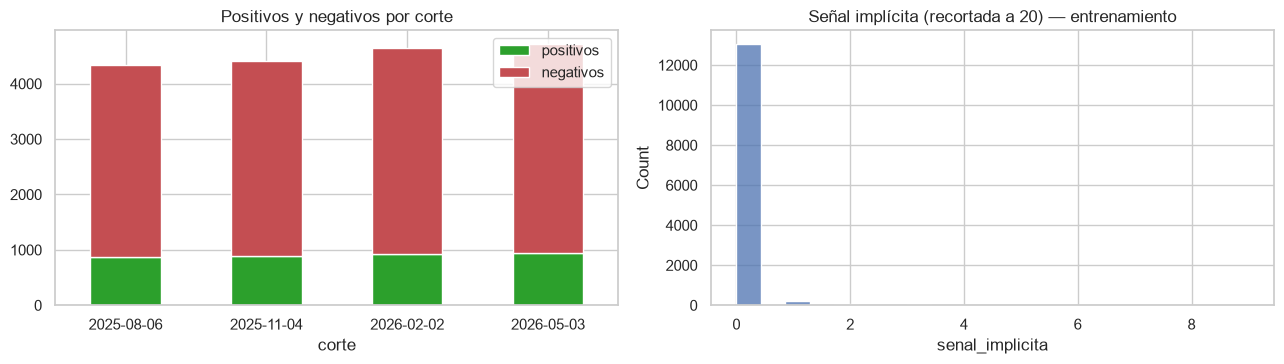

In [12]:
entrenamiento = dataset[dataset["corte"] < CORTE_VALIDACION].reset_index(drop=True)
validacion = dataset[dataset["corte"] == CORTE_VALIDACION].reset_index(drop=True)


def resumen_conjunto(df, nombre):
    return {"conjunto": nombre, "filas": len(df), "positivos": int(df["compra"].sum()),
            "negativos": int((df["compra"] == 0).sum()), "usuarios": df["usuario_id"].nunique(),
            "sku_distintos": df["sku"].nunique(), "% positivos": round(100 * df["compra"].mean(), 2)}


tabla_resumen = pd.DataFrame([resumen_conjunto(entrenamiento, "entrenamiento"),
                              resumen_conjunto(validacion, "validacion")])
display(tabla_resumen)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
dataset.groupby(dataset["corte"].dt.date)["compra"].agg(positivos="sum", total="size").assign(
    negativos=lambda x: x["total"] - x["positivos"])[["positivos", "negativos"]].plot.bar(
    stacked=True, ax=ax[0], rot=0, color=["#2CA02C", "#C44E52"])
ax[0].set_title("Positivos y negativos por corte"); ax[0].set_xlabel("corte")
sns.histplot(entrenamiento["senal_implicita"].clip(upper=20), bins=21, ax=ax[1], color="#4C72B0")
ax[1].set_title("Señal implícita (recortada a 20) — entrenamiento")
plt.tight_layout(); plt.show()

### 4.3 Candidatos para evaluar el ranking (validación y selección)
Las métricas de ranking (MAP@K, nDCG@K) **no** se pueden calcular sobre el muestreo de 4 negativos: hay que rankear el catálogo completo para cada usuario. Se genera la tabla `usuario × SKU` (sin lo ya comprado, solo SKU que existen en la ventana) con su etiqueta y exactamente los mismos predictores, **para dos cortes**:

- **Último corte (validación):** `ranking_validacion`. Es la evaluación final; el modelo nunca la usa para decidir nada.
- **Tercer corte (selección):** `ranking_seleccion`. En `03` sirve para **elegir hiperparámetros con nDCG@8** (el mismo criterio con que se evalúa al final), entrenando solo con los dos primeros cortes. Así la selección no toca la validación.

Ambas tablas incluyen **todos** los SKU y conservan la columna `recomendable`. Así, en `03` se pueden calcular las métricas **de las dos formas**: sobre todo el catálogo (calidad del modelo) y filtrando `recomendable` (lo que verá el cliente). Ver el diagnóstico 5.7: hoy `recomendable` descarta más de la mitad de las compras reales recientes.


In [13]:
def construir_ranking(corte):
    # Tabla usuario × SKU del corte, sin lo ya comprado, con la etiqueta y los mismos predictores del modelo.
    E = estados[corte]
    d_corte = dataset[dataset["corte"] == corte]
    positivos_c = (d_corte.loc[d_corte["compra"] == 1, ["usuario_id", "sku"]].astype(str)
                   .drop_duplicates().assign(compra=1))
    usuarios_c = positivos_c["usuario_id"].unique()
    # Candidatos: SKU que existen en la ventana + SKU realmente comprados en ella. Si `fecha_alta` es posterior
    # a una compra (dato inconsistente), el SKU claramente existía: se mantiene para no perder ese positivo.
    fp_c = E["fp"].assign(sku=E["fp"]["sku"].astype(str))
    forzados = set(positivos_c["sku"]) - set(fp_c.loc[fp_c["existe_en_ventana"], "sku"])
    if forzados:
        print(f"  [aviso] corte {corte.date()}: {len(forzados)} SKU con fecha_alta posterior a la ventana "
              f"pero comprados en ella; se incluyen como candidatos: {sorted(forzados)[:5]}")
    candidatos = fp_c[fp_c["existe_en_ventana"] | fp_c["sku"].isin(forzados)]["sku"].unique()

    grid = pd.DataFrame({"usuario_id": usuarios_c}).merge(pd.DataFrame({"sku": candidatos}), how="cross")
    prev_df = (E["hist"][["usuario_id", "sku"]].drop_duplicates()
               .astype(str).assign(_ya=1))
    grid = grid.merge(prev_df, on=["usuario_id", "sku"], how="left")
    grid = grid[grid["_ya"].isna()].drop(columns="_ya")          # no se recomienda lo ya comprado

    grid = grid.merge(positivos_c, on=["usuario_id", "sku"], how="left")
    grid["compra"] = grid["compra"].fillna(0).astype(int)
    grid["negativo_dificil"] = False
    grid["corte"] = corte

    rk = tratar_nulos(ensamblar(grid, E))
    assert int(rk["compra"].sum()) == len(positivos_c), "hay positivos fuera del grid"
    return rk, positivos_c, candidatos


# --- Último corte: evaluación final
E_val = estados[CORTE_VALIDACION]
ranking_validacion, positivos_val, cand_val = construir_ranking(CORTE_VALIDACION)
fuera_catalogo_rec = int(((ranking_validacion["compra"] == 1) & (~ranking_validacion["recomendable"])).sum())

print(f"[Validación · corte {CORTE_VALIDACION.date()}] Usuarios a rankear: {ranking_validacion['usuario_id'].nunique():,} · "
      f"SKU candidatos: {len(cand_val):,} "
      f"(de los cuales recomendables hoy: {int(ranking_validacion.drop_duplicates('sku')['recomendable'].sum()):,})")
print(f"Filas del grid: {len(ranking_validacion):,} · positivos: {int(ranking_validacion['compra'].sum()):,} "
      f"(todos dentro del grid)")
print(f"Positivos de SKU hoy NO recomendables: {fuera_catalogo_rec:,} "
      f"({pct(fuera_catalogo_rec, len(positivos_val)):.1f}%)")

# --- Tercer corte: selección de hiperparámetros en el notebook 03 (nunca se usa para evaluar)
CORTE_SELECCION = cortes[-2]
ranking_seleccion, positivos_sel, cand_sel = construir_ranking(CORTE_SELECCION)
print(f"\n[Selección · corte {CORTE_SELECCION.date()}] Usuarios a rankear: {ranking_seleccion['usuario_id'].nunique():,} · "
      f"SKU candidatos: {len(cand_sel):,} · filas: {len(ranking_seleccion):,} · "
      f"positivos: {int(ranking_seleccion['compra'].sum()):,}")


[Validación · corte 2026-05-03] Usuarios a rankear: 641 · SKU candidatos: 1,500 (de los cuales recomendables hoy: 597)
Filas del grid: 959,200 · positivos: 945 (todos dentro del grid)
Positivos de SKU hoy NO recomendables: 552 (58.4%)
  [aviso] corte 2026-02-02: 4 SKU con fecha_alta posterior a la ventana pero comprados en ella; se incluyen como candidatos: ['NX-10751', 'NX-10862', 'NX-10971', 'NX-11121']

[Selección · corte 2026-02-02] Usuarios a rankear: 640 · SKU candidatos: 1,477 · filas: 943,098 · positivos: 928


## 5. Validaciones

In [14]:
# ---- 5.1 Sin fuga de información, corte por corte
for corte, E in estados.items():
    assert E["hist"]["fecha_dt"].max() < corte, f"historial >= corte ({corte})"
    assert E["clk"]["timestamp_dt"].max() < corte, f"clickstream >= corte ({corte})"
    assert E["ev"]["fecha_dt"].min() >= corte and E["ev"]["fecha_dt"].max() < E["fin"], f"ventana mal definida ({corte})"
    print(f"[PASS] corte {corte.date()}: historial < corte, clickstream < corte, ventana [{corte.date()}, {E['fin'].date()})")

# ---- 5.2 Ventanas contiguas y sin solaparse; validación posterior al entrenamiento
for a, b in zip(cortes[:-1], cortes[1:]):
    assert a + pd.Timedelta(days=HORIZONTE_DIAS) == b, "ventanas no contiguas"
assert entrenamiento["corte"].max() < validacion["corte"].min()
print("[PASS] ventanas contiguas; todo el entrenamiento es anterior a la validación")
assert E_val["fin"] <= FIN_DATOS, "la ventana de validación pasa del fin de los datos"
print(f"[PASS] la ventana de validación termina el {E_val['fin'].date()} (fin de datos: {FIN_DATOS.date()})")

# ---- 5.3 Etiquetas: sin recompra, negativos limpios, sin duplicados
for corte, E in estados.items():
    d = dataset[dataset["corte"] == corte]
    pos_prev = sum(s in E["prev"].get(u, set()) for u, s in zip(d.loc[d.compra == 1, "usuario_id"].astype(str), d.loc[d.compra == 1, "sku"].astype(str)))
    neg = d[d.compra == 0]
    neg_mal = sum((s in E["prev"].get(u, set())) or (s in E["eval"].get(u, set()))
                  for u, s in zip(neg["usuario_id"].astype(str), neg["sku"].astype(str)))
    assert pos_prev == 0, f"positivos ya comprados antes ({corte})"
    assert neg_mal == 0, f"negativos comprados antes o en la ventana ({corte})"
    assert not d.duplicated(["usuario_id", "sku"]).any(), f"pares repetidos ({corte})"
print("[PASS] ningún positivo fue comprado antes del corte; ningún negativo fue comprado (antes o en la ventana); sin pares repetidos")

# ---- 5.4 Consentimiento y cuentas comodín
usuarios_dataset = set(dataset["usuario_id"].astype(str))
assert usuarios_dataset <= ids_consentidos, "hay usuarios sin consentimiento en el dataset"
assert not (usuarios_dataset & {u for u in usuarios_dataset if u.lower() in USUARIOS_EXCLUIDOS})
assert set(clickstream_limpio["usuario_id"].astype(str)) <= ids_consentidos
print(f"[PASS] los {len(usuarios_dataset):,} usuarios del dataset tienen consentimiento; sin 'UNKNOWN' ni 'invitado'")

# ---- 5.5 Sin nulos en los predictores y sin pares compartidos entre train y validación
assert dataset[FEATURES].isna().sum().sum() == 0
pos_tr = entrenamiento[entrenamiento["compra"] == 1]
pares_pos_tr = set(zip(pos_tr["usuario_id"].astype(str), pos_tr["sku"].astype(str)))
pares_va = set(zip(validacion["usuario_id"].astype(str), validacion["sku"].astype(str)))
assert not (pares_pos_tr & pares_va), "un par comprado en entrenamiento aparece en validación"
neg_tr = entrenamiento[entrenamiento["compra"] == 0]
repetidos = len(set(zip(neg_tr["usuario_id"].astype(str), neg_tr["sku"].astype(str))) & pares_va)
print("[PASS] sin nulos en predictores · ningún par COMPRADO en entrenamiento aparece en validación "
      "(no se recomienda lo ya comprado)")
print(f"       (informativo: {repetidos} pares usuario-SKU fueron negativos en entrenamiento y reaparecen en validación; "
      "es esperable en cortes distintos)")

[PASS] corte 2025-08-06: historial < corte, clickstream < corte, ventana [2025-08-06, 2025-11-04)
[PASS] corte 2025-11-04: historial < corte, clickstream < corte, ventana [2025-11-04, 2026-02-02)
[PASS] corte 2026-02-02: historial < corte, clickstream < corte, ventana [2026-02-02, 2026-05-03)
[PASS] corte 2026-05-03: historial < corte, clickstream < corte, ventana [2026-05-03, 2026-08-01)
[PASS] ventanas contiguas; todo el entrenamiento es anterior a la validación
[PASS] la ventana de validación termina el 2026-08-01 (fin de datos: 2026-08-01)
[PASS] ningún positivo fue comprado antes del corte; ningún negativo fue comprado (antes o en la ventana); sin pares repetidos
[PASS] los 1,527 usuarios del dataset tienen consentimiento; sin 'UNKNOWN' ni 'invitado'
[PASS] sin nulos en predictores · ningún par COMPRADO en entrenamiento aparece en validación (no se recomienda lo ya comprado)
       (informativo: 383 pares usuario-SKU fueron negativos en entrenamiento y reaparecen en validación; es

In [15]:
# ---- 5.6 Diagnóstico de sesgo: ¿se puede acertar sin mirar al usuario?
rec_set = set(productos_limpio.loc[productos_limpio["recomendable"], "sku"].astype(str))
d = validacion.assign(no_rec=lambda x: (~x["sku"].astype(str).isin(rec_set)).astype(int))

print("AUC de la popularidad sola (unidades_vendidas) en validación: "
      f"{roc_auc_score(d['compra'], d['unidades_vendidas']):.3f}   (≈ 0,5 = sin sesgo de popularidad)")
print("AUC del indicador 'SKU no recomendable' en validación:        "
      f"{roc_auc_score(d['compra'], d['no_rec']):.3f}   (≈ 0,5 = sin sesgo de stock)")
print(f"SKU no recomendables: positivos {100 * d.loc[d.compra == 1, 'no_rec'].mean():.1f}% · "
      f"negativos {100 * d.loc[d.compra == 0, 'no_rec'].mean():.1f}%")

con_int = dataset[(dataset["n_vistas"] + dataset["n_clics"] + dataset["n_agregados_carrito"]) > 0]
print(f"Filas con interacción previa: {len(con_int):,} · % positivas: {100 * con_int['compra'].mean():.1f}% "
      f"(base: {100 * dataset['compra'].mean():.1f}%) -> ver un producto debe AUMENTAR la probabilidad")
print(f"Positivos con alguna interacción previa: "
      f"{100 * ((dataset.loc[dataset.compra == 1, ['n_vistas', 'n_clics', 'n_agregados_carrito']].sum(axis=1)) > 0).mean():.1f}% "
      "(el clickstream es escaso: aporta poca señal)")

AUC de la popularidad sola (unidades_vendidas) en validación: 0.487   (≈ 0,5 = sin sesgo de popularidad)
AUC del indicador 'SKU no recomendable' en validación:        0.519   (≈ 0,5 = sin sesgo de stock)
SKU no recomendables: positivos 58.4% · negativos 54.5%
Filas con interacción previa: 481 · % positivas: 28.9% (base: 20.0%) -> ver un producto debe AUMENTAR la probabilidad
Positivos con alguna interacción previa: 3.8% (el clickstream es escaso: aporta poca señal)


In [16]:
# ---- 5.7 ¿Qué tan confiable es 'recomendable' como filtro? (hallazgo para negocio)
ult = E_val["ev"].merge(productos_limpio[["sku", "activo", "stock", "precio_lista", "recomendable"]], on="sku", how="left")
tabla_rec = pd.Series({
    "compras de la ventana de validación (líneas)": len(ult),
    "% de SKU hoy inactivos": 100 * (~ult["activo"]).mean(),
    f"% de SKU con stock < {STOCK_MINIMO} o desconocido": 100 * (ult["stock"].isna() | (ult["stock"] < STOCK_MINIMO)).mean(),
    "% de SKU con precio 0 o nulo": 100 * (ult["precio_lista"].isna() | (ult["precio_lista"] <= 0)).mean(),
    "% de compras de SKU recomendables hoy": 100 * ult["recomendable"].mean(),
    "(referencia) % del catálogo recomendable": 100 * productos_limpio["recomendable"].mean(),
}, name="valor").to_frame()
display(tabla_rec)
print("Si el % de compras recientes de SKU recomendables es parecido al % del catálogo, 'activo' y 'stock' "
      "no están relacionados con lo que realmente se vende: conviene validar esas columnas con operaciones/catálogo.")

,valor
compras de la ventana de validación (líneas),"1,233.00"
% de SKU hoy inactivos,36.33
% de SKU con stock < 3 o desconocido,32.77
% de SKU con precio 0 o nulo,2.43
% de compras de SKU recomendables hoy,42.66
(referencia) % del catálogo recomendable,39.80


Si el % de compras recientes de SKU recomendables es parecido al % del catálogo, 'activo' y 'stock' no están relacionados con lo que realmente se vende: conviene validar esas columnas con operaciones/catálogo.


## 6. Entregables
Se guardan en la carpeta de procesados. Todos los datos de personas **ya filtran por consentimiento**.

| Archivo | Contenido |
|---|---|
| `productos_limpio.csv`, `usuarios_limpio.csv`, `transacciones_limpio.csv`, `clickstream_limpio.csv` | Datos limpios (usuarios, compras y clics solo de quienes consintieron) |
| `entrenamiento.pkl` | Pares y predictores de los 3 primeros cortes |
| `validacion.pkl` | Pares y predictores del último corte (4 negativos por positivo) |
| `ranking_validacion.pkl` | Todo el catálogo existente por usuario en el último corte (con columna `recomendable`), para MAP@K / nDCG@K |
| `ranking_seleccion.pkl` | Igual que `ranking_validacion.pkl` pero para el **tercer corte**: se usa en `03` para elegir hiperparámetros con nDCG@8 |
| `sku_recomendables.pkl` | Catálogo sobre el que se puede recomendar en producción |
| `metadatos.pkl` | Parámetros, semilla, auditoría, cortes y decisiones |

In [17]:
productos_limpio.to_csv(OUT_DIR / "productos_limpio.csv", index=False)
usuarios_limpio.to_csv(OUT_DIR / "usuarios_limpio.csv", index=False)
transacciones_limpio.to_csv(OUT_DIR / "transacciones_limpio.csv", index=False)
clickstream_limpio.to_csv(OUT_DIR / "clickstream_limpio.csv", index=False)

sku_recomendables = sorted(productos_limpio.loc[productos_limpio["recomendable"], "sku"].astype(str))

metadatos = {
    "fin_datos": FIN_DATOS, "horizonte_dias": HORIZONTE_DIAS, "cortes": cortes,
    "corte_validacion": CORTE_VALIDACION, "stock_minimo": STOCK_MINIMO,
    "negativos_por_positivo": NEGATIVOS_POR_POSITIVO, "dificiles_por_positivo": DIFICILES_POR_POSITIVO,
    "pop_alpha": POP_ALPHA, "random_state": RANDOM_STATE,
    "corte_seleccion": CORTE_SELECCION, "ventanas_tendencia": VENTANAS_TENDENCIA,
    "recencia_sin_compra": RECENCIA_SIN_COMPRA, "suavizado_afinidad": SUAVIZADO_AFINIDAD,
    "features": FEATURES, "columnas_no_predictor": NO_PREDICTORES,
    "resumen_limpieza": tabla_auditoria, "resumen_cortes": resumen_cortes,
    "resumen_entrenamiento_validacion": tabla_resumen,
    "medianas_antiguedad": medianas_antiguedad,
    "usuarios_con_consentimiento": len(ids_consentidos),
    "usuarios_sin_consentimiento_excluidos": len(usuarios_total) - len(ids_consentidos),
    "positivos_validacion_fuera_de_recomendables": fuera_catalogo_rec,
    "notas": [
        "solo usuarios con consentimiento (acepta_marketing == 1)",
        "no se recomienda lo ya comprado: positivos y negativos excluyen compras previas al corte",
        "negativos del catálogo completo ponderados por popularidad previa al corte",
        "el filtro 'recomendable' (stock de hoy) se aplica al servir y al evaluar el ranking, no al entrenar",
        "validación temporal: el último corte de 90 días",
        "stock >= STOCK_MINIMO; precio_sospechoso marca SKU con costo > precio (error de carga)",
    ],
    "versiones": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}

joblib.dump(entrenamiento, OUT_DIR / "entrenamiento.pkl")
joblib.dump(validacion, OUT_DIR / "validacion.pkl")
joblib.dump(ranking_validacion, OUT_DIR / "ranking_validacion.pkl", compress=3)
joblib.dump(ranking_seleccion, OUT_DIR / "ranking_seleccion.pkl", compress=3)
joblib.dump(sku_recomendables, OUT_DIR / "sku_recomendables.pkl")
joblib.dump(metadatos, OUT_DIR / "metadatos.pkl")

print(f"Entregables guardados en {OUT_DIR}:")
for _f in sorted(OUT_DIR.iterdir()):
    print(f"  {_f.name:30s} {_f.stat().st_size:>12,} bytes")

Entregables guardados en C:\Users\Gabo\Documents\modelo-nexus arquitectura\modelo-nexus\datos\procesados:
  clickstream_limpio.csv              593,092 bytes
  entrenamiento.pkl                 3,146,870 bytes
  metadatos.pkl                         8,789 bytes
  productos_limpio.csv                131,964 bytes
  ranking_seleccion.pkl             5,505,328 bytes
  ranking_validacion.pkl            5,652,198 bytes
  sku_recomendables.pkl                 6,583 bytes
  transacciones_limpio.csv          1,135,999 bytes
  usuarios_limpio.csv                 116,812 bytes
  validacion.pkl                    1,113,054 bytes


## 7. Resumen

In [18]:
resumen_final = pd.Series({
    "Usuarios con consentimiento (se usan)": len(ids_consentidos),
    "Usuarios sin consentimiento (excluidos)": len(usuarios_total) - len(ids_consentidos),
    "Líneas de compra válidas": len(transacciones_limpio),
    "Eventos de clickstream válidos": len(clickstream_limpio),
    "SKU recomendables": len(sku_recomendables),
    "Cortes (90 días cada uno)": len(cortes),
    "Positivos entrenamiento": int(entrenamiento["compra"].sum()),
    "Positivos validación": int(validacion["compra"].sum()),
    "Filas del grid de ranking (validación)": len(ranking_validacion),
    "Filas del grid de ranking (selección)": len(ranking_seleccion),
}, name="valor")
display(resumen_final.to_frame())

,valor
Usuarios con consentimiento (se usan),2077
Usuarios sin consentimiento (excluidos),1923
Líneas de compra válidas,9770
Eventos de clickstream válidos,5933
SKU recomendables,597
Cortes (90 días cada uno),4
Positivos entrenamiento,2680
Positivos validación,945
Filas del grid de ranking (validación),959200
Filas del grid de ranking (selección),943098


### Próximo paso
`03_modelado.ipynb`:
1. **Baseline de más vendidos** (la popularidad sola) sobre `ranking_validacion.pkl`: cualquier modelo debe superarlo.
2. Elegir hiperparámetros con **nDCG@8 sobre `ranking_seleccion.pkl`** (tercer corte), entrenar con `entrenamiento.pkl` y evaluarlo con **MAP@K y nDCG@K** sobre `ranking_validacion.pkl` (sin lo ya comprado), de dos formas: sobre todo el catálogo y solo sobre SKU `recomendable`.
3. Serializar el modelo con `joblib`.

**Pendientes de negocio:** confirmar con catálogo los 32 SKU con `precio_sospechoso` y los SKU `NX-9xxxx`; confirmar con cumplimiento que `acepta_marketing` cubre el perfilamiento; confirmar con operaciones el umbral `STOCK_MINIMO`.